# Module 1: Business Understanding & Synthetic Contextual Data Generation
**Project:** House Price Prediction for a Real Estate Listing Platform (Ames, Iowa)

## Objectives
1. Define the core valuation business problem, asymmetric error costs, and KPI targets.
2. Load the base Kaggle Ames Housing dataset (`train.csv` and `test.csv`).
3. Generate 13 realistic, deterministic synthetic contextual features (`seed=42`) covering neighborhood amenities, renovation history, days on market, and macroeconomic indicators.
4. Validate data integrity, ranges, and business realism.

In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, os.path.abspath('..'))
from src.data_generation import run_module_1, validate_synthetic_data, SYNTHETIC_COLUMNS

sns.set_theme(style='whitegrid')

## 1. Run Deterministic Synthetic Data Pipeline

In [2]:
train_aug, test_aug = run_module_1(data_dir='../data', output_dir='../data/processed', seed=42)
print('Train shape:', train_aug.shape)
print('Test shape:', test_aug.shape)
train_aug[SYNTHETIC_COLUMNS].head()

2026-11-26 12:34:09,548 [INFO] Loading raw Kaggle datasets...
2026-11-26 12:34:13,236 [INFO] Saved ../data/processed\train_augmented.csv | Validation stats: {'rows': 1460, 'columns': 94, 'missing_synthetic': 0, 'renovation_rate_pct': 54.45, 'avg_dom': 40.5, 'avg_amenity_score': 60.82}
2026-11-26 12:34:18,128 [INFO] Saved ../data/processed\test_augmented.csv | Validation stats: {'rows': 1459, 'columns': 93, 'missing_synthetic': 0, 'renovation_rate_pct': 52.02, 'avg_dom': 39.93, 'avg_amenity_score': 60.73}


Train shape: (1460, 94)
Test shape: (1459, 93)


,distance_to_school_km,distance_to_hospital_km,distance_to_transit_km,amenity_composite_score,has_renovation,renovation_type,renovation_cost_usd,renovation_contractor,renovation_permit_id,days_on_market,mortgage_rate_pct,local_price_index,unemployment_rate_pct
0,1.337,4.013,0.460,59.75,0,None,0.00,None,None,66,5.91,98.64,4.22
1,1.662,3.797,0.732,51.32,0,None,0.00,None,None,42,6.27,104.71,3.86
2,1.197,4.266,0.323,63.14,1,Cosmetic,11171.03,"Guzman, Hoffman and Baldwin",PRM-2002-78227,27,6.15,99.35,4.15
3,1.358,2.596,0.429,66.73,1,Kitchen_Bath,33145.78,Morales-Jones,PRM-1970-77027,36,6.35,101.92,3.77
4,2.235,4.579,0.883,39.44,0,None,0.00,None,None,28,6.10,99.06,4.27


## 2. Summary Statistics & Sanity Verification

In [3]:
stats = validate_synthetic_data(train_aug)
print('Validation Summary:', stats)
display(train_aug[SYNTHETIC_COLUMNS].describe().T)

Validation Summary: {'rows': 1460, 'columns': 94, 'missing_synthetic': 0, 'renovation_rate_pct': 54.45, 'avg_dom': 40.5, 'avg_amenity_score': 60.82}


,count,mean,std,min,25%,50%,75%,max
distance_to_school_km,1460.0,1.332614,0.625489,0.308,0.82125,1.2270,1.73000,3.439
distance_to_hospital_km,1460.0,3.346577,1.402658,0.521,2.26100,3.5185,4.46325,6.572
distance_to_transit_km,1460.0,0.555954,0.314183,0.080,0.33300,0.4450,0.75525,1.684
amenity_composite_score,1460.0,60.815651,17.127122,25.000,48.19000,63.7750,74.54500,91.430
has_renovation,1460.0,0.544521,0.498185,0.000,0.00000,1.0000,1.00000,1.000
renovation_cost_usd,1460.0,10764.220007,16633.158829,0.000,0.00000,6297.7150,13017.08750,125000.000
days_on_market,1460.0,40.495890,21.131349,9.000,26.00000,36.0000,50.00000,209.000
mortgage_rate_pct,1460.0,5.775685,0.673827,4.510,5.04000,6.0600,6.35000,6.560
local_price_index,1460.0,98.932719,4.628581,90.760,93.53750,99.9450,103.15000,105.110
unemployment_rate_pct,1460.0,4.655993,1.058140,3.400,3.77000,4.1400,5.99000,6.440


## 3. Visual Realism Check of Generated Features

2026-11-26 12:34:23,625 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
C:\Users\Jonathan\AppData\Local\Temp\ipykernel_22996\2314296543.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train_aug, x='YrSold', y='mortgage_rate_pct', ax=axes[1, 1], palette='Blues')
2026-11-26 12:34:23,705 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


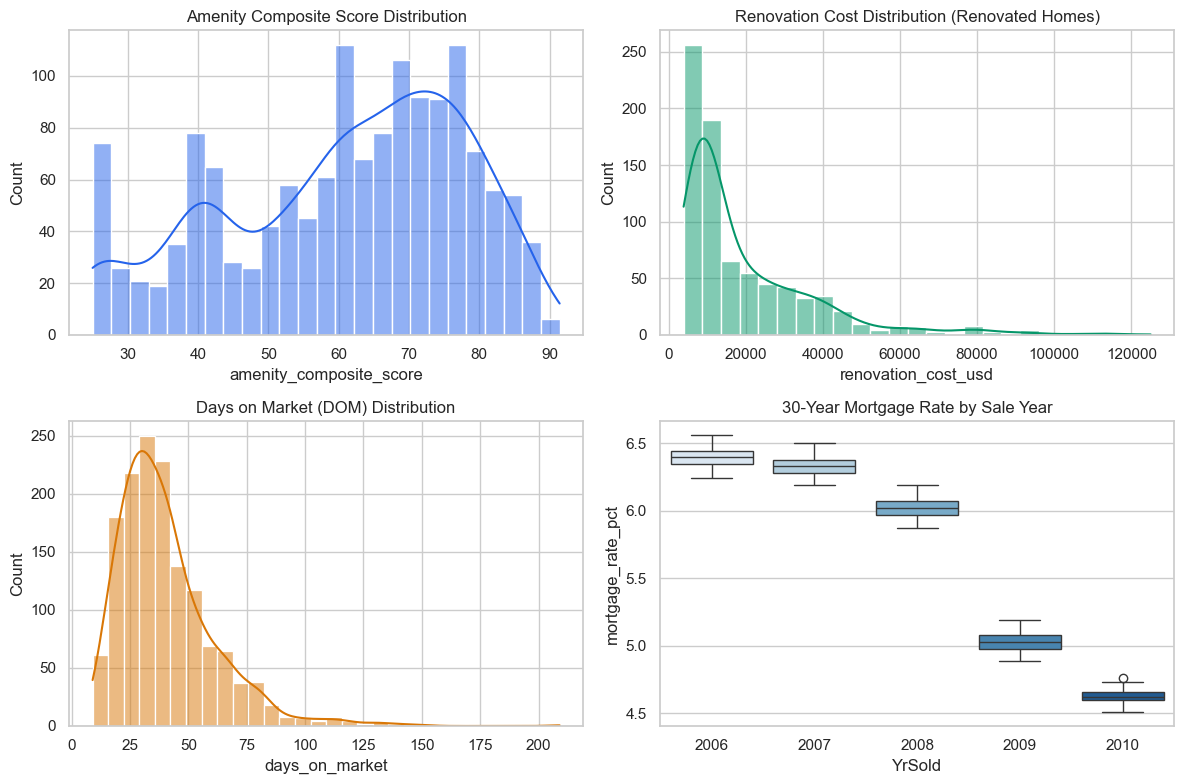

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(train_aug['amenity_composite_score'], bins=25, kde=True, ax=axes[0, 0], color='#2563eb')
axes[0, 0].set_title('Amenity Composite Score Distribution')

sns.histplot(train_aug.loc[train_aug['has_renovation'] == 1, 'renovation_cost_usd'], bins=25, kde=True, ax=axes[0, 1], color='#059669')
axes[0, 1].set_title('Renovation Cost Distribution (Renovated Homes)')

sns.histplot(train_aug['days_on_market'], bins=30, kde=True, ax=axes[1, 0], color='#d97706')
axes[1, 0].set_title('Days on Market (DOM) Distribution')

sns.boxplot(data=train_aug, x='YrSold', y='mortgage_rate_pct', ax=axes[1, 1], palette='Blues')
axes[1, 1].set_title('30-Year Mortgage Rate by Sale Year')

plt.tight_layout()
plt.show()